<a href="https://colab.research.google.com/github/nahsiz/99_days_of_coding_MLOps_With_CPC/blob/main/phase-1/day_19/day_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import Required Libraries

Text Box Title: Importing Required Libraries

Text Box Description: Import Pandas, NumPy, Matplotlib, and Seaborn for data analysis, correlation analysis, and data quality checks.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Load the Dataset

Text Box Title: Loading the World Happiness Report 2015 Dataset

Text Box Description: Load the CSV file into a Pandas DataFrame and strip any extra whitespace from column names so the long bracketed column names work correctly.

In [18]:
data = pd.read_csv('/content/2015.csv')
data.columns = data.columns.str.strip()

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


3. Display First 5 Rows

Text Box Title: Displaying the First 5 Rows

Text Box Description: Use the head() function to quickly verify the dataset was loaded correctly.

In [19]:
data.head()

,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Switzerland,Western Europe,1,7.587,0.03411,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738
1,Iceland,Western Europe,2,7.561,0.04884,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201
2,Denmark,Western Europe,3,7.527,0.03328,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204
3,Norway,Western Europe,4,7.522,0.03880,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2.46531
4,Canada,North America,5,7.427,0.03553,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2.45176


4. Dataset Shape and Information

Text Box Title: Checking Dataset Dimensions and Data Types

Text Box Description: Identify total rows and columns, then inspect column names, data types, and non-null counts using info().

In [20]:
print("Total Rows:", data.shape[0])
print("Total Columns:", data.shape[1])
print()
data.info()

Total Rows: 158
Total Columns: 12

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        158 non-null    object 
 1   Region                         158 non-null    object 
 2   Happiness Rank                 158 non-null    int64  
 3   Happiness Score                158 non-null    float64
 4   Standard Error                 158 non-null    float64
 5   Economy (GDP per Capita)       158 non-null    float64
 6   Family                         158 non-null    float64
 7   Health (Life Expectancy)       158 non-null    float64
 8   Freedom                        158 non-null    float64
 9   Trust (Government Corruption)  158 non-null    float64
 10  Generosity                     158 non-null    float64
 11  Dystopia Residual              158 non-null    float64
dtypes: float64(9), 

5. Check Missing Values

Text Box Title: Detecting Missing Values in Each Column

Text Box Description: Count missing values per column to identify any data quality issue before analysis.

In [21]:
missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print("No missing values found in the dataset.")
else:
    print("Missing values per column:")
    print(missing)

No missing values found in the dataset.


6. Check Duplicate Rows

Text Box Title: Detecting Duplicate Rows

Text Box Description: Count duplicate rows in the dataset to check whether duplicate records need to be handled before correlation analysis.

In [22]:
duplicate_count = data.duplicated().sum()

print("Total duplicate rows:", duplicate_count)
print("Duplicate percentage:", round((duplicate_count / len(data)) * 100, 2), "%")

Total duplicate rows: 0
Duplicate percentage: 0.0 %


7. Check Outliers (IQR Method on GDP)

Text Box Title: Detecting Outliers in the Economy (GDP per Capita) Column

Text Box Description: Use the IQR method to count outliers in the Economy (GDP per Capita) column, since GDP is our shared x-axis and extreme GDP values (Qatar, Luxembourg, Singapore) can distort the scatter plots and correlation values.

In [23]:
gdp_col = 'Economy (GDP per Capita)'

Q1 = data[gdp_col].quantile(0.25)
Q3 = data[gdp_col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data[(data[gdp_col] < lower_bound) | (data[gdp_col] > upper_bound)]

print("Q1:", round(Q1, 4), "| Q3:", round(Q3, 4), "| IQR:", round(IQR, 4))
print("Lower bound:", round(lower_bound, 4), "| Upper bound:", round(upper_bound, 4))
print("Number of GDP outliers:", len(outliers))
print("Outlier percentage:", round((len(outliers) / len(data)) * 100, 2), "%")

Q1: 0.5458 | Q3: 1.1584 | IQR: 0.6126
Lower bound: -0.3732 | Upper bound: 2.0774
Number of GDP outliers: 0
Outlier percentage: 0.0 %


8. Select Four Columns (Shared X-Axis)

Text Box Title: Selecting Four Columns for Correlation Analysis

Text Box Description: Select one shared x-axis column (Economy (GDP per Capita)) and three y-axis columns (Happiness Score, Health (Life Expectancy), Freedom). GDP per capita will stay on the x-axis in all scatter plots so the three relationships can be compared against the same horizontal axis.

In [24]:
x_col = 'Economy (GDP per Capita)'
y_col_1 = 'Happiness Score'
y_col_2 = 'Health (Life Expectancy)'
y_col_3 = 'Freedom'

selected_data = data[[x_col, y_col_1, y_col_2, y_col_3]]

selected_data.head()

,Economy (GDP per Capita),Happiness Score,Health (Life Expectancy),Freedom
0,1.39651,7.587,0.94143,0.66557
1,1.30232,7.561,0.94784,0.62877
2,1.32548,7.527,0.87464,0.64938
3,1.45900,7.522,0.88521,0.66973
4,1.32629,7.427,0.90563,0.63297


9. Calculate Pearson Correlation

Text Box Title: Calculating Correlation Between Four Columns

Text Box Description: Calculate the Pearson correlation coefficient three times — GDP per capita vs Happiness Score, GDP per capita vs Health (Life Expectancy), and GDP per capita vs Freedom. GDP per capita remains the shared x-axis column in all three calculations.

In [25]:
correlation_1 = selected_data[x_col].corr(selected_data[y_col_1])
correlation_2 = selected_data[x_col].corr(selected_data[y_col_2])
correlation_3 = selected_data[x_col].corr(selected_data[y_col_3])

print("Correlation between", x_col, "and", y_col_1)
print("Pearson Correlation Coefficient:", round(correlation_1, 4))
print()
print("Correlation between", x_col, "and", y_col_2)
print("Pearson Correlation Coefficient:", round(correlation_2, 4))
print()
print("Correlation between", x_col, "and", y_col_3)
print("Pearson Correlation Coefficient:", round(correlation_3, 4))

Correlation between Economy (GDP per Capita) and Happiness Score
Pearson Correlation Coefficient: 0.781

Correlation between Economy (GDP per Capita) and Health (Life Expectancy)
Pearson Correlation Coefficient: 0.8165

Correlation between Economy (GDP per Capita) and Freedom
Pearson Correlation Coefficient: 0.3703


10. Correlation Heatmap (4×4)

Text Box Title: Visualizing Correlation Using a Heatmap

Text Box Description: Create a 4×4 heatmap to display the correlation coefficients between all four selected columns at a glance.

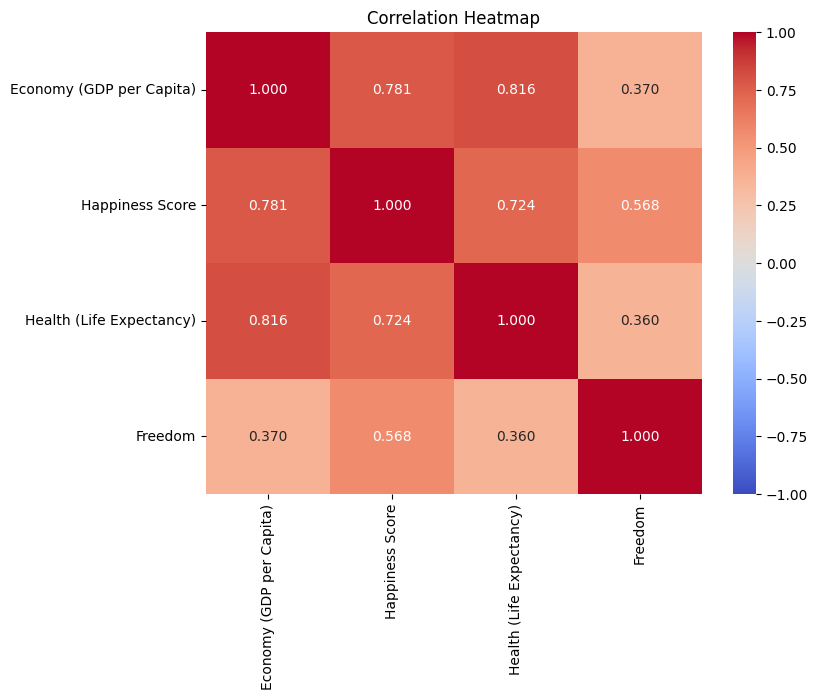

In [26]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    selected_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap')
plt.show()

11. Scatter Plot — Shared X with First Y

Text Box Title: Visualizing GDP per Capita vs Happiness Score

Text Box Description: Create a scatter plot with a regression line where Economy (GDP per Capita) is on the x-axis and Happiness Score is on the y-axis. GDP stays on the x-axis because it is the shared axis for all three plots.

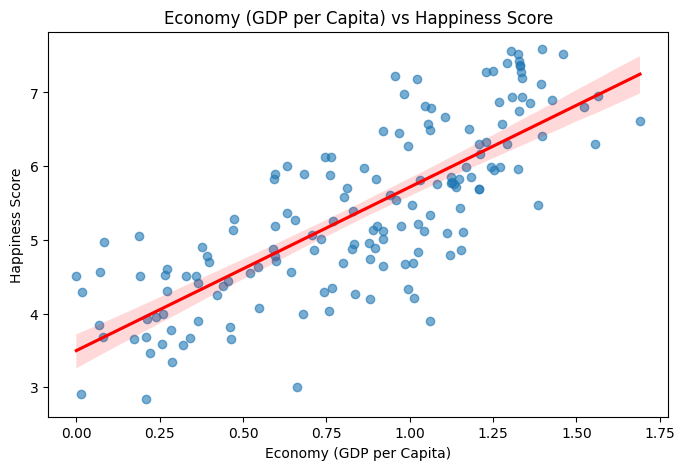

In [27]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_1,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_1}')
plt.xlabel(x_col)
plt.ylabel(y_col_1)
plt.show()

12. Scatter Plot — Shared X with Second Y

Text Box Title: Visualizing GDP per Capita vs Health (Life Expectancy)

Text Box Description: Create a scatter plot with a regression line where Economy (GDP per Capita) is again on the x-axis, but Health (Life Expectancy) is now on the y-axis. The x-axis stays identical to the previous plot so both relationships share the same horizontal axis.

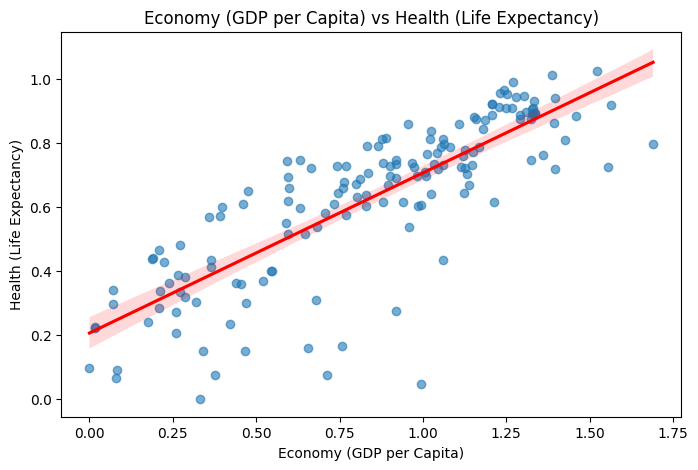

In [28]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_2,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_2}')
plt.xlabel(x_col)
plt.ylabel(y_col_2)
plt.show()

13. Scatter Plot — Shared X with Third Y

Text Box Title: Visualizing GDP per Capita vs Freedom

Text Box Description: Create a scatter plot with a regression line where Economy (GDP per Capita) is again on the x-axis, but Freedom is now on the y-axis. The x-axis stays identical so all three plots share the same horizontal axis.

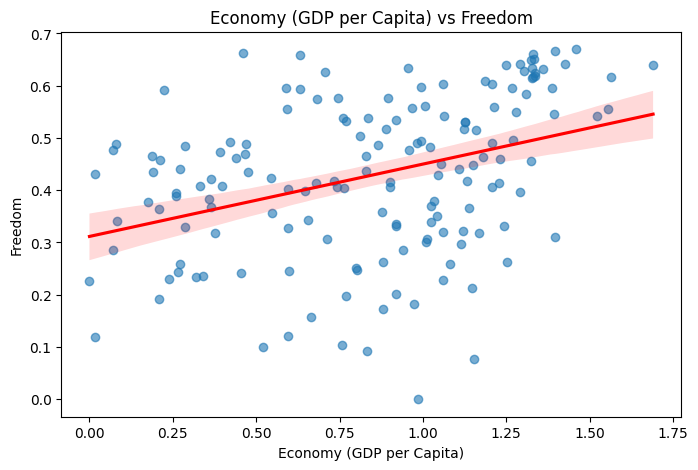

In [29]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_3,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_3}')
plt.xlabel(x_col)
plt.ylabel(y_col_3)
plt.show()

14. Histograms — Check Skew and Spikes

Text Box Title: Visualizing Distributions to Detect Skew

Text Box Description: Plot histograms with KDE curves for all four selected columns side by side to detect which distributions are skewed, bimodal, or have odd spikes. This supports the histogram-based finding in NOTES.md.

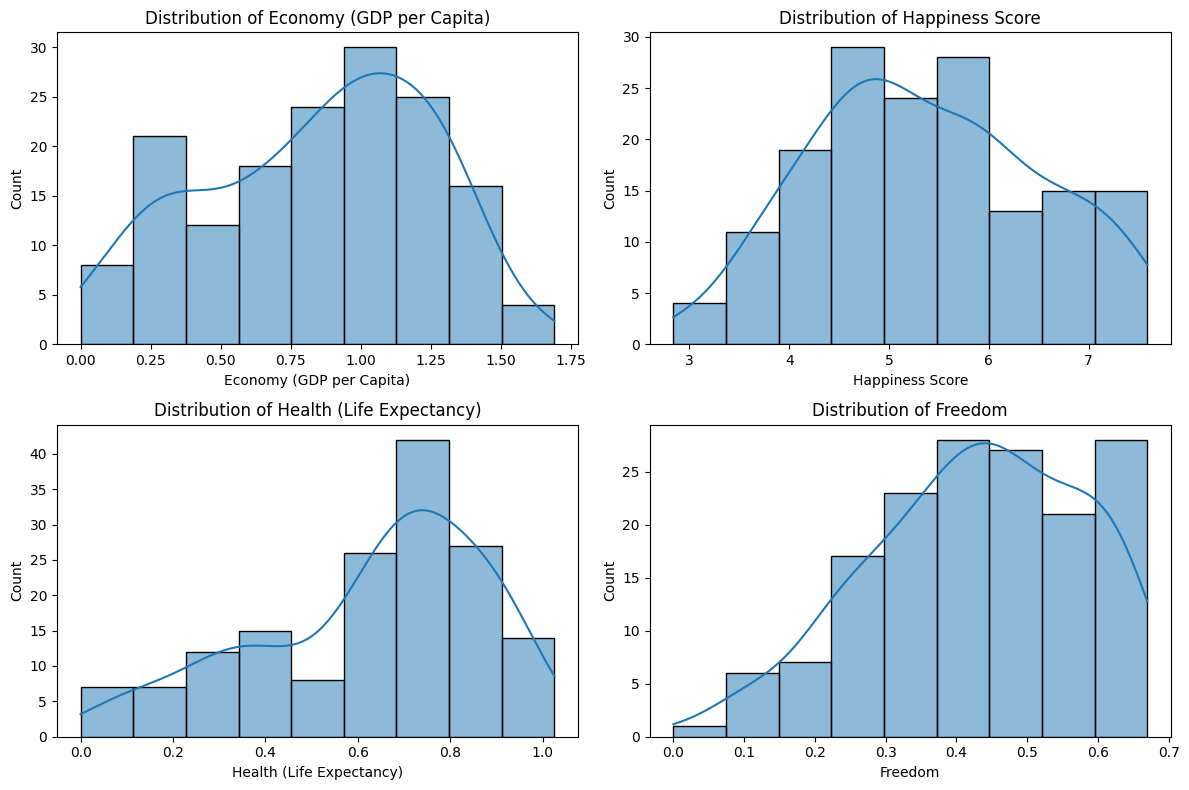

Skewness of Economy (GDP per Capita) : -0.3176
Skewness of Happiness Score : 0.0978
Skewness of Health (Life Expectancy) : -0.7053
Skewness of Freedom : -0.4135


In [30]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data[x_col], kde=True, ax=axes[0, 0])
axes[0, 0].set_title(f'Distribution of {x_col}')

sns.histplot(data[y_col_1], kde=True, ax=axes[0, 1])
axes[0, 1].set_title(f'Distribution of {y_col_1}')

sns.histplot(data[y_col_2], kde=True, ax=axes[1, 0])
axes[1, 0].set_title(f'Distribution of {y_col_2}')

sns.histplot(data[y_col_3], kde=True, ax=axes[1, 1])
axes[1, 1].set_title(f'Distribution of {y_col_3}')

plt.tight_layout()
plt.show()

print("Skewness of", x_col, ":", round(data[x_col].skew(), 4))
print("Skewness of", y_col_1, ":", round(data[y_col_1].skew(), 4))
print("Skewness of", y_col_2, ":", round(data[y_col_2].skew(), 4))
print("Skewness of", y_col_3, ":", round(data[y_col_3].skew(), 4))

15. Interpret the Correlation Results

Text Box Title: Interpreting All Three Correlation Coefficients

Text Box Description: Identify whether each relationship between GDP per capita and the three y-columns is positive, negative, or has no linear correlation.

In [31]:
for label, value in [(y_col_1, correlation_1),
                     (y_col_2, correlation_2),
                     (y_col_3, correlation_3)]:
    print(f"{x_col} vs {label}")
    if value > 0:
        print("  Positive Correlation")
    elif value < 0:
        print("  Negative Correlation")
    else:
        print("  No Linear Correlation")
    print("  Correlation Value:", round(value, 4))
    print()

Economy (GDP per Capita) vs Happiness Score
  Positive Correlation
  Correlation Value: 0.781

Economy (GDP per Capita) vs Health (Life Expectancy)
  Positive Correlation
  Correlation Value: 0.8165

Economy (GDP per Capita) vs Freedom
  Positive Correlation
  Correlation Value: 0.3703



16. Display Final Correlation Result

Text Box Title: Final Correlation Analysis Result

Text Box Description: Display the shared x-axis column name and all three y-axis column names along with their calculated Pearson correlation coefficients.

In [32]:
print("Final Correlation Analysis")
print("--------------------------")

print("Shared X-Axis Column :", x_col)
print("First Y-Axis Column  :", y_col_1)
print("Pearson Correlation  :", round(correlation_1, 4))
print()

print("Shared X-Axis Column :", x_col)
print("Second Y-Axis Column :", y_col_2)
print("Pearson Correlation  :", round(correlation_2, 4))
print()

print("Shared X-Axis Column :", x_col)
print("Third Y-Axis Column  :", y_col_3)
print("Pearson Correlation  :", round(correlation_3, 4))

Final Correlation Analysis
--------------------------
Shared X-Axis Column : Economy (GDP per Capita)
First Y-Axis Column  : Happiness Score
Pearson Correlation  : 0.781

Shared X-Axis Column : Economy (GDP per Capita)
Second Y-Axis Column : Health (Life Expectancy)
Pearson Correlation  : 0.8165

Shared X-Axis Column : Economy (GDP per Capita)
Third Y-Axis Column  : Freedom
Pearson Correlation  : 0.3703
